In [1]:
#Imports
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, BatchNormalization, Activation, Dropout, LeakyReLU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping


In [2]:
# Hyperparameters

# Architecture: monotone funnel, sized for ~800k-row 18-dataset pool with the expanded feature set.
# This replaces the old [30, 162, 88, 95, 24]. The 30->162 expansion in the old shape was almost
# certainly an HPO artefact; a monotone funnel trains more stably and converges in fewer epochs.
hidden_layers = 4
hl1_neurons = 512
hl2_neurons = 420
hl3_neurons = 320
hl4_neurons = 224
hl5_neurons = 48

# Training
ActivationFunction = 'relu'
OptimizerAlgorithm = 'adam'

# Huber on STANDARDISED Cp residuals.
# delta=0.5 (standardised) ≈ 0.2 in raw Cp units, given Cp_train.std() ≈ 0.4.
# Small enough to be MAE-like for residuals beyond ~0.2 raw Cp.
LossFunction = keras.losses.Huber(delta=0.5)

LearningRate = 0.004
Patience = 30          # slightly more patient on the larger pool
Epochs = 250
BatchSize = 1024        # larger batch for the larger dataset

In [3]:
#Model Architecture (parametric, up to 5 hidden layers)

# Define neurons for up to 5 layers (only first hidden_layers values are used)
neurons_vector = [hl1_neurons, hl2_neurons, hl3_neurons, hl4_neurons, hl5_neurons]

# Validation
if not (1 <= hidden_layers <= 5):
    raise ValueError("hidden_layers must be between 1 and 5")
if len(neurons_vector) != 5:
    raise ValueError("neurons_vector must contain exactly 5 values")
if any(n <= 0 for n in neurons_vector):
    raise ValueError("all neuron counts must be positive integers")

# Build selected architecture from first N entries
selected_layers = neurons_vector[:hidden_layers]

# Keep compatibility with the rest of the notebook
architectures = {
    'custom': selected_layers
}
selected_arch = 'custom'

print(f"Selected architecture: {selected_arch} -> {architectures[selected_arch]}")

Selected architecture: custom -> [512, 420, 320, 224]


In [4]:

# Load data
data_path = os.path.join("ProcessedData", "compiled_processed_features.csv")
df = pd.read_csv(data_path)

target_col = "Cp"
meta_cols = {"dataset_name", "surface_id"}  # not features, but kept for split/grouping

if target_col not in df.columns:
    raise ValueError(f"Target column '{target_col}' not found in dataset.")
if "surface_id" not in df.columns:
    raise ValueError(
        "Column 'surface_id' is missing from the compiled CSV. "
        "Re-run the patched FeatureEngine_B notebook (it now persists surface_id)."
    )
if "dataset_name" not in df.columns:
    raise ValueError("Column 'dataset_name' is missing from the compiled CSV.")

# === Predict Cp directly (no residual reformulation, no face-mean leakage) ===
Y_raw = pd.to_numeric(df[target_col], errors="coerce").to_numpy(dtype=float)

# Candidate features: exclude metadata and the target itself
candidate_feature_cols = [c for c in df.columns if c not in meta_cols and c != target_col]
feature_cols = [c for c in candidate_feature_cols if pd.api.types.is_numeric_dtype(df[c])]
dropped_non_numeric = [c for c in candidate_feature_cols if c not in feature_cols]

# Sanity check: ensure no Cp-derived columns slipped in
forbidden = {"neighbor_cp_mean", "neighbor_cp_std", "Cp_face_mean", "Cp_face_std"}
leaked = [c for c in feature_cols if c in forbidden]
if leaked:
    raise ValueError(f"Target leakage: remove these from the CSV before training: {leaked}")

if not feature_cols:
    raise ValueError("No numeric feature columns found after filtering metadata columns.")

DROP_FEATURES_DEAD = {
    # Constants/near-constants on the 18-set pool. The 15-set list also had
    # `upstream_separation_score`, `bldg_AR_DB`, `face_is_underside` here, but on
    # the 18-set pool the first two came alive (curved geometries break the
    # square-plan symmetry; the bug-fixed upstream-curvature now contributes).
    # `face_is_underside` is now non-constant (0.00144 importance) but still at
    # the noise floor — kept in drop list as low-value rather than truly dead.
    "roughness_rms":
        "all geometries are NURBS-defined planes; numerical zero (std~1e-14)",
    "face_is_underside":
        "near-noise importance (0.001) on 18-set pool; one-hot rarely set",
    #"neighbor_z_variance":
     #   "importance 0.008, no strong correlation partner; reconsider on full pool",
    "bldg_AR_DB":
        "near-constant ≈ 1 on 17/18 datasets; one outlier (Waves at 45°) creates "
        "extreme standardised values when held-out folds also have AR_DB≠1, causing "
        "training explosion. Reintroduce if the data pool gains non-square-plan geometries.",
}
DROP_FEATURES_REDUNDANT = {
    # ρ ≥ 0.9 with a partner that the model is keeping; importance is being
    # split between the pair. Drop the less-interpretable / less-physically-grounded
    # member of each pair.
    "wind_angle_rad":         "ρ=1.000 with wind_sin (the wrap-safe pair); raw radian redundant",
    "roof_tilt_rad":          "ρ=1.000 with roof_tilt_sin in the sampled tilt range; raw radian redundant",
    "bldg_D":                 "ρ=0.99 with bldg_B; both encode wind-rel bbox extent (now slightly distinct on Waves at 45°)",
    "face_normal_azimuth_cos": "ρ=0.92 with nx_rel; the continuous-azimuth encoding duplicates nx_rel for faceted geometries",
    "face_normal_polar_rad":  "ρ=0.99 with nz_rel; arccos(nz_rel) is monotone-equivalent",
    # face_normal_azimuth_sin is NOT dropped — though ρ=0.88 with ny_rel, the
    # cap is below 0.9 and on the full pool with more curved geometries the
    # azimuth encoding will provide signal that nx/ny_rel cannot.
}
DROP_FEATURES = {**DROP_FEATURES_DEAD, **DROP_FEATURES_REDUNDANT}

actually_dropped = [c for c in feature_cols if c in DROP_FEATURES]
not_present = [c for c in DROP_FEATURES if c not in feature_cols]
feature_cols = [c for c in feature_cols if c not in DROP_FEATURES]   

print(f"Trimming features: {len(actually_dropped)} dropped, {len(not_present)} already absent")
if actually_dropped:
    print("  Dropped:")
    for c in actually_dropped:
        kind = "DEAD     " if c in DROP_FEATURES_DEAD else "REDUNDANT"
        print(f"    [{kind}] {c}  — {DROP_FEATURES[c]}")
if not_present:
    print("  Already absent (probably trimmed at FeatureEngine stage):")
    for c in not_present:
        print(f"    {c}")

X_raw = df[feature_cols].to_numpy(dtype=float)

print(f"\nFeature columns used: {len(feature_cols)} (was {len(feature_cols) + len(actually_dropped)} before trim)")
print("Dropped non-numeric feature columns:", dropped_non_numeric)
print("Target: Cp (absolute, no residual reformulation)")
print("X shape:", X_raw.shape)
print("Y shape:", Y_raw.shape)

Trimming features: 8 dropped, 0 already absent
  Dropped:
    [DEAD     ] roughness_rms  — all geometries are NURBS-defined planes; numerical zero (std~1e-14)
    [REDUNDANT] wind_angle_rad  — ρ=1.000 with wind_sin (the wrap-safe pair); raw radian redundant
    [REDUNDANT] bldg_D  — ρ=0.99 with bldg_B; both encode wind-rel bbox extent (now slightly distinct on Waves at 45°)
    [DEAD     ] bldg_AR_DB  — near-constant ≈ 1 on 17/18 datasets; one outlier (Waves at 45°) creates extreme standardised values when held-out folds also have AR_DB≠1, causing training explosion. Reintroduce if the data pool gains non-square-plan geometries.
    [REDUNDANT] roof_tilt_rad  — ρ=1.000 with roof_tilt_sin in the sampled tilt range; raw radian redundant
    [DEAD     ] face_is_underside  — near-noise importance (0.001) on 18-set pool; one-hot rarely set
    [REDUNDANT] face_normal_polar_rad  — ρ=0.99 with nz_rel; arccos(nz_rel) is monotone-equivalent
    [REDUNDANT] face_normal_azimuth_cos  — ρ=0.92 with

In [5]:
#Data preprocessing
# Keep raw arrays here; scaling is performed after split to avoid leakage
X = X_raw
Y = Y_raw

In [6]:
# Data Split: hold out one diagnostic dataset; split remaining into train/val.
# With 18 datasets including curved geometries, Monopitch_0d is no longer the right
# single hold-out. Pick one of the diagnostic options below or set HOLD_OUT_NAME directly.

TestFrac = 0.15  # used only if no specific hold-out matches
ValFrac = 0.15

# Pick ONE diagnostic hold-out. Change this string to test different generalisation modes.
# Recommended starting choice: a curved geometry at 45° (hardest single test).
HOLD_OUT_NAME = "CFDDataHyperbolicRoof10_0d"  # tests transfer to curved geometry + steep angle (hardest single test)

# Other diagnostic choices:
#   "CFDDataDome10_0d"               -> tests transfer to a curved geometry, 0° flow
#   "CFDDataMonoPitchRoof15d_45d"    -> tests transfer to an unseen roof tilt at 45°
#   "CFDDataGableRoof5d_22.5d"       -> tests transfer to an intermediate wind angle

if "dataset_name" not in df.columns:
    raise ValueError("Expected column 'dataset_name' is missing.")

all_idx = np.arange(len(df))
all_names = df["dataset_name"].astype(str)
test_mask = (all_names == HOLD_OUT_NAME).values
idx_test = all_idx[test_mask]
idx_non_test = all_idx[~test_mask]

if len(idx_test) == 0:
    print(f"Hold-out '{HOLD_OUT_NAME}' not found. Available datasets:")
    for d in sorted(all_names.unique()):
        print(f"  {d}")
    print(f"Falling back to a random {TestFrac:.0%} test split.")
    idx_trainval, idx_test = train_test_split(all_idx, test_size=TestFrac, random_state=42)
    val_within_trainval = ValFrac / (1 - TestFrac)
    idx_train, idx_val = train_test_split(idx_trainval, test_size=val_within_trainval, random_state=42)
else:
    test_frac_actual = len(idx_test) / len(df)
    val_within_trainval = ValFrac / (1 - test_frac_actual)
    idx_train, idx_val = train_test_split(idx_non_test, test_size=val_within_trainval, random_state=42)

# Per-dataset row counts (sanity check that nothing was silently truncated)
print("Rows per dataset (train+val+test):")
for d in sorted(all_names.unique()):
    n = (all_names == d).sum()
    role = "TEST" if d == HOLD_OUT_NAME else "train/val"
    print(f"  {n:>7}  {d:<35}  ({role})")

X_train_raw = X_raw[idx_train]; Y_train_raw = Y_raw[idx_train]
X_val_raw   = X_raw[idx_val];   Y_val_raw   = Y_raw[idx_val]
X_test_raw  = X_raw[idx_test];  Y_test_raw  = Y_raw[idx_test]

# Scale after split: fit only on train
scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_train = scaler_x.fit_transform(X_train_raw)
X_val   = scaler_x.transform(X_val_raw)
X_test  = scaler_x.transform(X_test_raw)
Y_train = scaler_y.fit_transform(Y_train_raw.reshape(-1, 1)).ravel()
Y_val   = scaler_y.transform(Y_val_raw.reshape(-1, 1)).ravel()
Y_test  = scaler_y.transform(Y_test_raw.reshape(-1, 1)).ravel()

print(f"\nTrain/Val/Test shapes: {X_train.shape}, {Y_train.shape}, {X_val.shape}, {Y_val.shape}, {X_test.shape}, {Y_test.shape}")
print(f"Train Cp range: [{Y_train_raw.min():.3f}, {Y_train_raw.max():.3f}], mean={Y_train_raw.mean():.3f}")
print(f"Test  Cp range: [{Y_test_raw.min():.3f}, {Y_test_raw.max():.3f}], mean={Y_test_raw.mean():.3f}")

Rows per dataset (train+val+test):
    12541  CFDDataDome05_0d                     (train/val)
    49706  CFDDataDome10_0d                     (train/val)
   105526  CFDDataDome16_0d                     (train/val)
    57219  CFDDataFlatRoof178L_0d               (train/val)
    57148  CFDDataFlatRoof178L_45d              (train/val)
    57227  CFDDataFlatRoof178L_90d              (train/val)
    57219  CFDDataFlatRoof178W_0d               (train/val)
    57148  CFDDataFlatRoof178W_45d              (train/val)
    57227  CFDDataFlatRoof178W_90d              (train/val)
    57046  CFDDataFlatRoof89H_0d                (train/val)
    57052  CFDDataFlatRoof89H_45d               (train/val)
    57071  CFDDataFlatRoof89H_90d               (train/val)
    42799  CFDDataFlatRoof_0d                   (train/val)
    42812  CFDDataFlatRoof_11.25d               (train/val)
    42864  CFDDataFlatRoof_22.5d                (train/val)
    42817  CFDDataFlatRoof_45d                  (train/val)
    4

In [7]:
#Build and compile model with selected architecture

def build_ffn(layer_sizes, input_dim, use_bn=True, dropout=0.0, lr=LearningRate):
    model = keras.Sequential()
    model.add(keras.Input(shape=(input_dim,)))

    if len(layer_sizes) == 0:
        model.add(Dense(1, activation='linear'))
        model.compile(optimizer=Adam(learning_rate=lr), loss=LossFunction, metrics=['mae'])
        return model

    for size in layer_sizes:
        model.add(Dense(size, use_bias=not use_bn, kernel_initializer='he_normal'))
        if use_bn:
            model.add(BatchNormalization())
        model.add(Activation(ActivationFunction))
        if dropout > 0:
            model.add(Dropout(dropout))

    model.add(Dense(1, activation='linear'))
    model.compile(optimizer=Adam(learning_rate=lr), loss=LossFunction, metrics=['mae'])
    return model

model = build_ffn(architectures[selected_arch], input_dim=X_train.shape[1], use_bn=True, dropout=0.0)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 420)            │       215,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 420)            │         1,680 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 420)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 320)            │       134,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 320)            │         1,280 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 224)            │        71,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224)            │           896 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,193 (1.70 MB)

 Trainable params: 443,241 (1.69 MB)

 Non-trainable params: 2,952 (11.53 KB)

In [8]:
# Stratified mini-batch sampling by geometry family.
#
# Each batch contains ~batch_size / n_families samples from each family, regardless of
# family size. The largest family (likely Wavy Roof in the full pool) is fully traversed
# over multiple "epochs" rather than dominating any single batch.

import re as _re

def classify_family(dataset_name):
    """Map a dataset name to a coarse geometry family. Used by the stratified sampler.
    Keep in sync with the LOGO-CV cell's _classify_dataset (same families, same logic)."""
    n = str(dataset_name).lower()
    if "dome" in n: return "dome"
    if "waves" in n or "wavy" in n: return "waves"
    if "flatroof" in n: return "flatroof"
    if "gableroof" in n or "gable" in n: return "gableroof"
    if "monopitchroof" in n or "monopitch" in n: return "monopitch"
    if "box" in n: return "box"
    return "other"


class StratifiedFamilySequence(keras.utils.Sequence):
    """
    Yields (X_batch, Y_batch, sample_weight_batch) drawn proportionally from each
    geometry family. Designed for use with `model.fit(seq, validation_data=...)`.

    Parameters
    ----------
    X, Y, sample_weights : np.ndarray
        Pre-scaled training arrays in the same row order as `family_labels`.
    family_labels : array-like of str
        One label per row of X. Rows are grouped by label internally.
    batch_size : int
        Total samples per batch. Per-family quota = batch_size // n_families,
        with the remainder distributed round-robin.
    shuffle : bool
        Re-shuffle each family's index pool at every epoch boundary.
    seed : int
        Base seed for reproducible shuffling.
    """
    def __init__(self, X, Y, sample_weights, family_labels, batch_size,
                 shuffle=True, seed=0):
        super().__init__()
        assert len(X) == len(Y) == len(sample_weights) == len(family_labels), \
            "All inputs must have matching length"
        self.X = X
        self.Y = Y
        self.W = sample_weights
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.rng = np.random.RandomState(seed)
        # Build per-family index arrays in the order the families first appear
        labels = np.asarray(family_labels)
        self.families = sorted(np.unique(labels).tolist())
        self.fam_indices = {f: np.where(labels == f)[0].copy() for f in self.families}
        self.fam_sizes = {f: len(self.fam_indices[f]) for f in self.families}
        # Per-family quota inside one batch
        n_fam = len(self.families)
        base = self.batch_size // n_fam
        rem = self.batch_size - base * n_fam
        # Distribute remainder to the largest families so they run out last
        size_order = sorted(self.families, key=lambda f: -self.fam_sizes[f])
        self.fam_quota = {f: base for f in self.families}
        for f in size_order[:rem]:
            self.fam_quota[f] += 1
        # Steps per epoch defined by the largest family (so its full pool is visited once)
        max_size = max(self.fam_sizes.values())
        max_quota = max(self.fam_quota.values())
        self.steps_per_epoch = int(np.ceil(max_size / max_quota))
        # Per-family read cursor; reset/shuffle on epoch boundary
        self.fam_cursor = {f: 0 for f in self.families}
        self._shuffle_all()

    def _shuffle_all(self):
        if self.shuffle:
            for f in self.families:
                self.rng.shuffle(self.fam_indices[f])
        for f in self.families:
            self.fam_cursor[f] = 0

    def _take(self, family, n):
        """Pull n indices from `family`, cycling and re-shuffling on exhaustion."""
        pool = self.fam_indices[family]
        size = len(pool)
        if size == 0:
            return np.empty(0, dtype=int)
        cur = self.fam_cursor[family]
        if cur + n <= size:
            out = pool[cur:cur + n]
            self.fam_cursor[family] = cur + n
        else:
            # Wrap: take what's left, reshuffle, take the rest from the start
            tail = pool[cur:]
            if self.shuffle:
                self.rng.shuffle(self.fam_indices[family])
            head = self.fam_indices[family][:n - len(tail)]
            out = np.concatenate([tail, head])
            self.fam_cursor[family] = n - len(tail)
        return out

    def __len__(self):
        return self.steps_per_epoch

    def __getitem__(self, _step):
        idx_parts = [self._take(f, self.fam_quota[f]) for f in self.families]
        idx = np.concatenate(idx_parts)
        # Light intra-batch shuffle so the loss/optimiser don't see family blocks contiguously
        self.rng.shuffle(idx)
        return self.X[idx], self.Y[idx], self.W[idx]

    def on_epoch_end(self):
        self._shuffle_all()


def make_stratified_sequence(X, Y, weights, df_subset_indices, df_full, batch_size,
                             shuffle=True, seed=0):
    """Convenience: build a StratifiedFamilySequence given positional indices into df_full."""
    fam_labels = df_full.loc[df_subset_indices, "dataset_name"].map(classify_family).to_numpy()
    return StratifiedFamilySequence(X, Y, weights, fam_labels, batch_size,
                                    shuffle=shuffle, seed=seed)


print("✓ StratifiedFamilySequence helper defined")

✓ StratifiedFamilySequence helper defined


In [9]:
# Train model — uses stratified-family mini-batches via StratifiedFamilySequence.
early_stop = EarlyStopping(monitor="val_loss", patience=Patience, restore_best_weights=True, verbose=1)

# === Sample weighting (unchanged from previous patch) ===
# These are per-tap multipliers applied inside each batch by the sequence.
if "dist_to_nearest_edge_H" in df.columns:
    edge_dist_train = pd.to_numeric(df.loc[idx_train, "dist_to_nearest_edge_H"], errors="coerce").to_numpy(dtype=float)
    edge_dist_val   = pd.to_numeric(df.loc[idx_val,   "dist_to_nearest_edge_H"], errors="coerce").to_numpy(dtype=float)
    edge_dist_train = np.nan_to_num(edge_dist_train, nan=0.5)
    edge_dist_val   = np.nan_to_num(edge_dist_val,   nan=0.5)
    cap = 0.3
    edge_train_score = 1.0 - np.clip(np.abs(edge_dist_train), 0.0, cap) / cap
    edge_val_score   = 1.0 - np.clip(np.abs(edge_dist_val),   0.0, cap) / cap
    edge_weight_train = 1.0 + 1.5 * edge_train_score
    edge_weight_val   = 1.0 + 1.5 * edge_val_score
else:
    edge_weight_train = np.ones(len(idx_train), dtype=float)
    edge_weight_val   = np.ones(len(idx_val),   dtype=float)

cp_train_raw = pd.to_numeric(df.loc[idx_train, "Cp"], errors="coerce").to_numpy(dtype=float)
cp_val_raw   = pd.to_numeric(df.loc[idx_val,   "Cp"], errors="coerce").to_numpy(dtype=float)
cp_train_raw = np.nan_to_num(cp_train_raw, nan=0.0)
cp_val_raw   = np.nan_to_num(cp_val_raw,   nan=0.0)
cp_mean_train = float(cp_train_raw.mean())
TAIL_CAP = 1.0
abs_dev_train = np.clip(np.abs(cp_train_raw - cp_mean_train), 0.0, TAIL_CAP) / TAIL_CAP
abs_dev_val   = np.clip(np.abs(cp_val_raw   - cp_mean_train), 0.0, TAIL_CAP) / TAIL_CAP
tail_weight_train = 1.0 + 1.0 * abs_dev_train
tail_weight_val   = 1.0 + 1.0 * abs_dev_val

combined_weights_train = edge_weight_train * tail_weight_train
combined_weights_val   = edge_weight_val   * tail_weight_val

print(f"Edge weights (train):  mean={edge_weight_train.mean():.3f}, max={edge_weight_train.max():.3f}")
print(f"Tail weights (train):  mean={tail_weight_train.mean():.3f}, max={tail_weight_train.max():.3f}")
print(f"Combined (train):      mean={combined_weights_train.mean():.3f}, max={combined_weights_train.max():.3f}")

# === Stratified mini-batch sequences ===
train_seq = make_stratified_sequence(
    X_train, Y_train, combined_weights_train,
    df_subset_indices=idx_train, df_full=df, batch_size=BatchSize,
    shuffle=True, seed=0,
)
val_seq = make_stratified_sequence(
    X_val, Y_val, combined_weights_val,
    df_subset_indices=idx_val, df_full=df, batch_size=BatchSize,
    shuffle=False, seed=0,   # deterministic val ordering
)

# Diagnostic: how many samples per family does one training batch contain?
print(f"\nStratified sampler: {len(train_seq.families)} families, batch_size={BatchSize}")
for f in train_seq.families:
    print(f"  {f:<12}: pool={train_seq.fam_sizes[f]:>7}, per-batch quota={train_seq.fam_quota[f]:>3}")
print(f"  Steps per epoch: {len(train_seq)} (driven by largest family)")

history = model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=Epochs,
    callbacks=[early_stop],
    verbose=1,
)

Edge weights (train):  mean=1.000, max=1.000
Tail weights (train):  mean=1.320, max=2.000
Combined (train):      mean=1.320, max=2.000

Stratified sampler: 6 families, batch_size=1024
  dome        : pool= 142379, per-batch quota=170
  flatroof    : pool= 618227, per-batch quota=171
  gableroof   : pool= 886233, per-batch quota=171
  monopitch   : pool=1701104, per-batch quota=171
  other       : pool= 949288, per-batch quota=171
  waves       : pool= 520161, per-batch quota=170
  Steps per epoch: 9948 (driven by largest family)
Epoch 1/250
9948/9948 ━━━━━━━━━━━━━━━━━━━━ 254s 25ms/step - loss: 0.0222 - mae: 0.0970 - val_loss: 0.0123 - val_mae: 0.0637
Epoch 2/250
9948/9948 ━━━━━━━━━━━━━━━━━━━━ 252s 25ms/step - loss: 0.0117 - mae: 0.0626 - val_loss: 0.0090 - val_mae: 0.0495
Epoch 3/250
9948/9948 ━━━━━━━━━━━━━━━━━━━━ 251s 25ms/step - loss: 0.0096 - mae: 0.0534 - val_loss: 0.0080 - val_mae: 0.0449
Epoch 4/250
9948/9948 ━━━━━━━━━━━━━━━━━━━━ 251s 25ms/step - loss: 0.0085 - mae: 0.0488 - val_

In [10]:
# performance evaluation on train / validation / test sets

def evaluate_split(split_name, X_split, Y_split):
    y_pred_scaled = model.predict(X_split, verbose=0).ravel()

    # Inverse-transform Cp back to the original scale
    y_true_orig = scaler_y.inverse_transform(Y_split.reshape(-1, 1)).ravel()
    y_pred_orig = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    mae_value = mean_absolute_error(y_true_orig, y_pred_orig)
    mse_value = mean_squared_error(y_true_orig, y_pred_orig)
    r2_value = r2_score(y_true_orig, y_pred_orig)

    print(f"{split_name} MAE: {mae_value:.4f}, MSE: {mse_value:.4f}, R²: {r2_value:.4f}")
    return y_true_orig, y_pred_orig, mae_value, mse_value, r2_value

print("Model performance:")
y_train_orig, y_train_pred_orig, train_mae, train_mse, train_r2 = evaluate_split("Train", X_train, Y_train)
y_val_orig, y_val_pred_orig, val_mae, val_mse, val_r2 = evaluate_split("Validation", X_val, Y_val)
y_test_orig, y_pred_orig, mae, mse, r2 = evaluate_split("Test", X_test, Y_test)

# Diagnostics dataframe for plotting (keeps original metadata)
df_test_diag = df.iloc[idx_test].copy().reset_index(drop=True)
df_test_diag["Cp_true"] = y_test_orig
df_test_diag["Cp_pred"] = y_pred_orig
df_test_diag["residual"] = df_test_diag["Cp_true"] - df_test_diag["Cp_pred"]

# Per-dataset MAE breakdown (sanity)
print("\nPer-dataset MAE on test split:")
print(df_test_diag.groupby("dataset_name")["residual"].apply(lambda r: r.abs().mean()))

Model performance:
Train MAE: 0.0098, MSE: 0.0011, R²: 0.9955
Validation MAE: 0.0102, MSE: 0.0014, R²: 0.9943
Test MAE: 0.4929, MSE: 0.7161, R²: -7.6223

Per-dataset MAE on test split:
dataset_name
CFDDataHyperbolicRoof10_0d    0.492854
Name: residual, dtype: float64


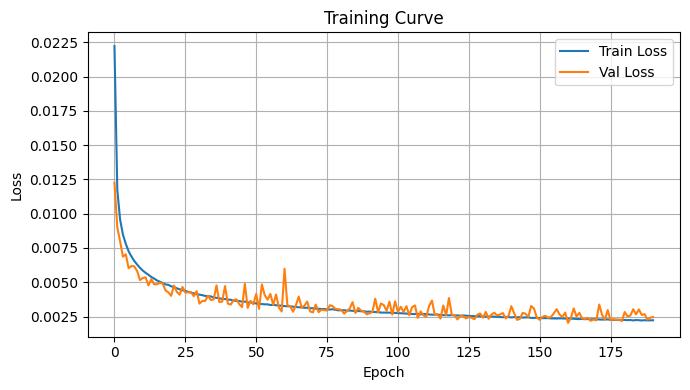

In [11]:
                                                                
#Training curve
plt.figure(figsize=(7,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

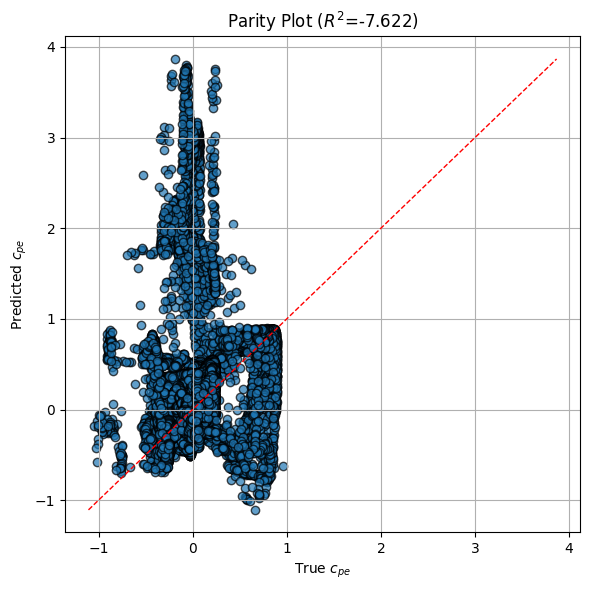

In [12]:
#parity plot
plt.figure(figsize=(6,6))
plt.scatter(y_test_orig, y_pred_orig, alpha=0.7, edgecolor='k')
mn = min(y_test_orig.min(), y_pred_orig.min())
mx = max(y_test_orig.max(), y_pred_orig.max())
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=1)
plt.xlabel('True $c_{pe}$')
plt.ylabel('Predicted $c_{pe}$')
plt.title(f'Parity Plot ($R^2$={r2:.3f})')
plt.grid(True)
plt.tight_layout()
plt.show()

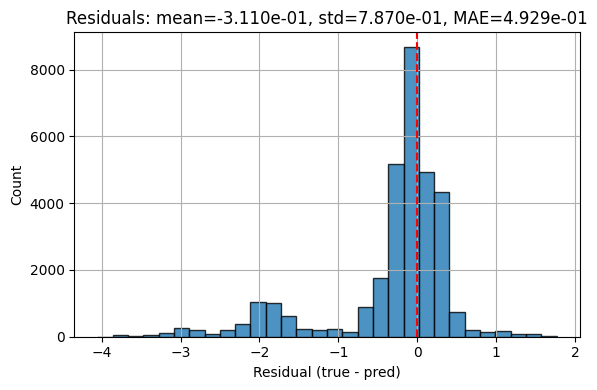

In [13]:
#Residual histogram

res = y_test_orig - y_pred_orig
plt.figure(figsize=(6,4))
plt.hist(res, bins=30, color='C0', edgecolor='k', alpha=0.8)
plt.axvline(0, color='r', linestyle='--')
plt.title(f'Residuals: mean={res.mean():.3e}, std={res.std():.3e}, MAE={mae:.3e}')
plt.xlabel('Residual (true - pred)')
plt.ylabel('Count')
plt.grid(True)
plt.tight_layout()
plt.show()

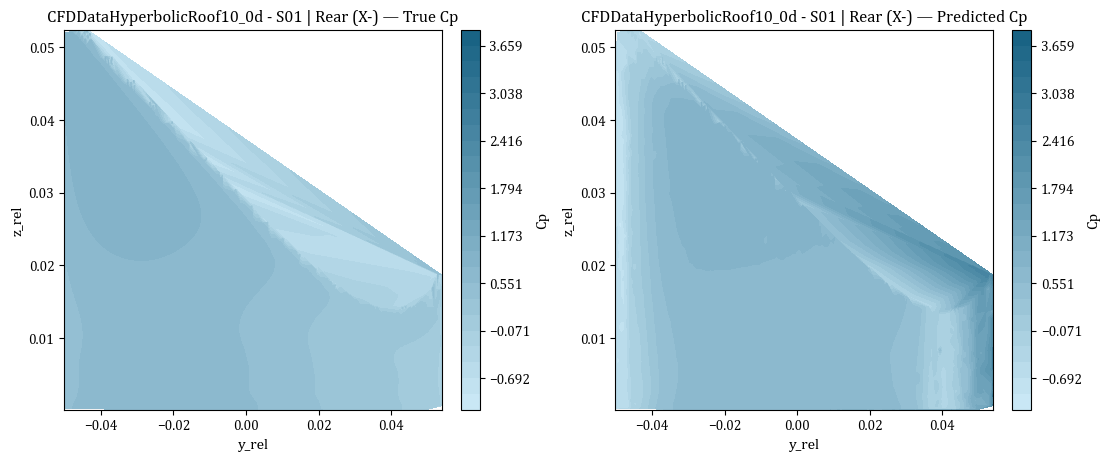

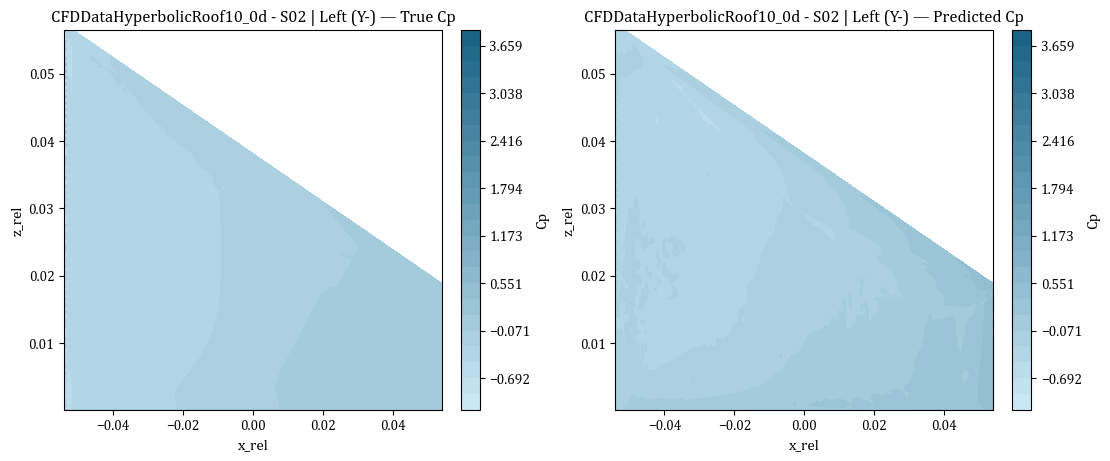

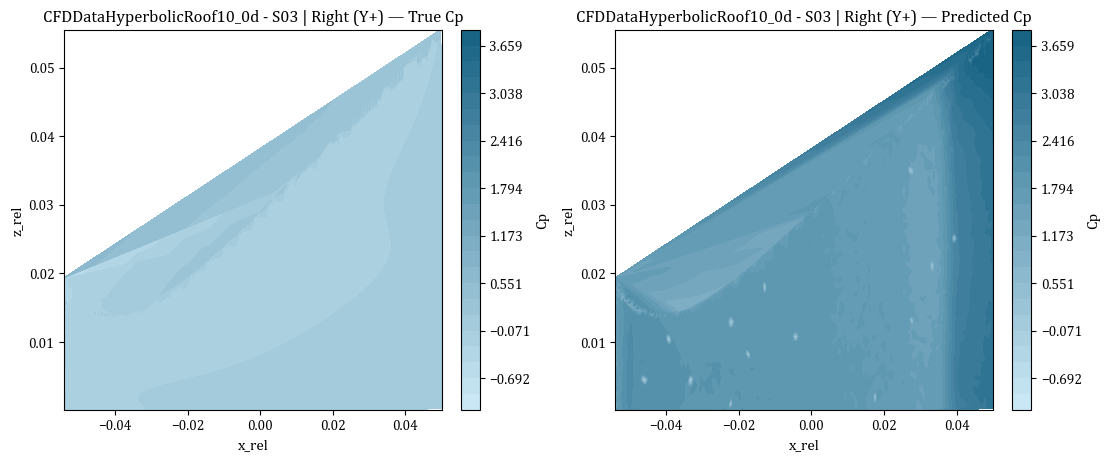

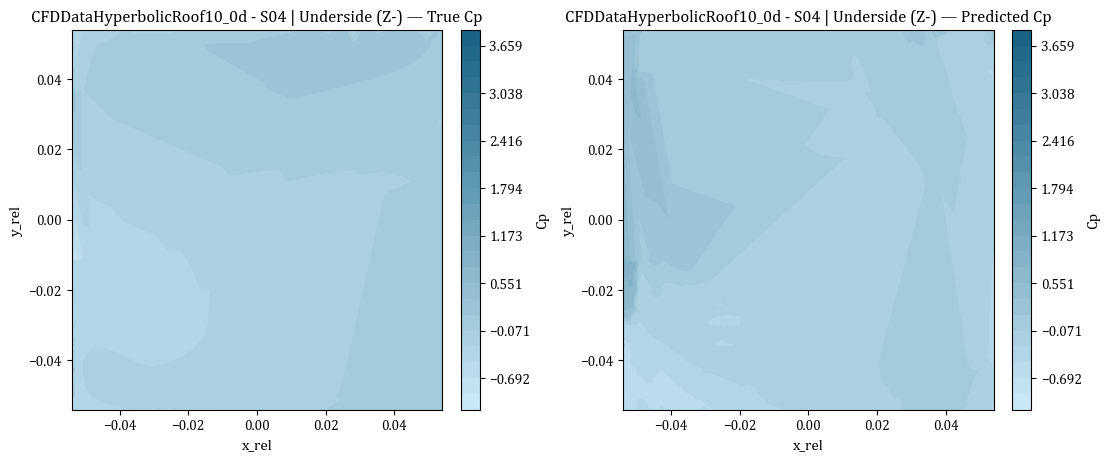

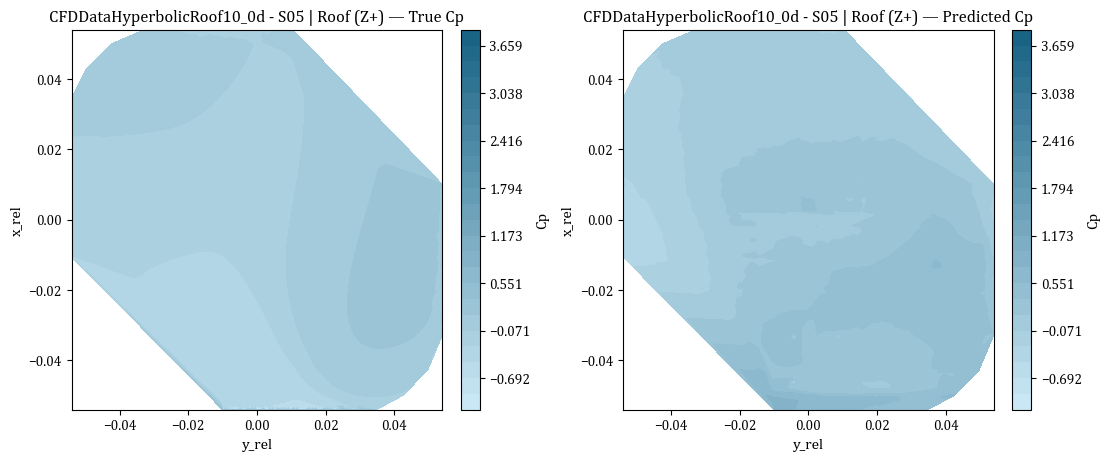

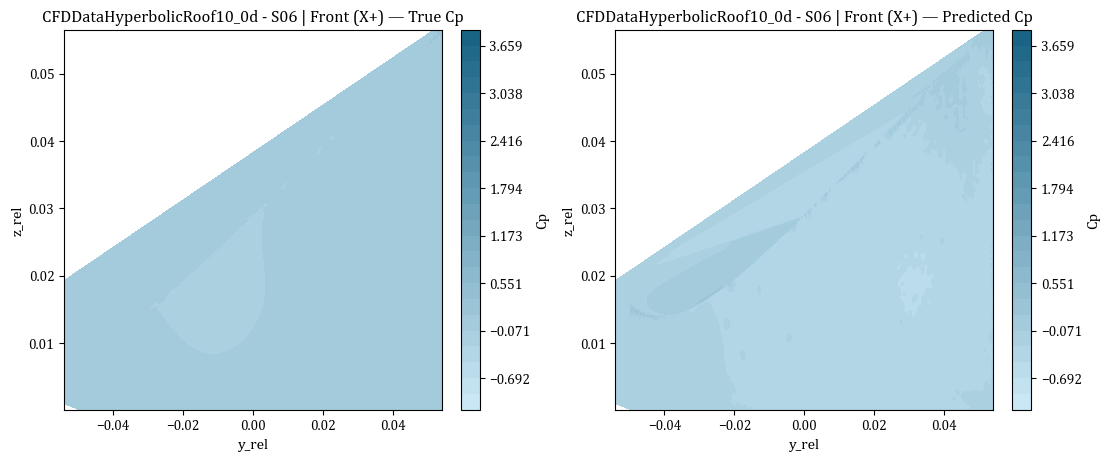


Generated 6 figures (one per surface).
Available signature columns: ['area_from_export', 'curvature_proxy_mean_rad', 'roughness_rms', 'verticality_abs_nz', 'wind_pos_norm']
Missing signature columns (ignored): ['curvature_proxy_max_rad', 'normal_dispersion_std_rad', 'neighbor_curv_anchor_wmean', 'opp_normal_dot_anchor', 'opp_anchor_dist']
Grouping rule: dominant-axis orientation is ignored for Gable to avoid over-splitting
Surfaces in test split by geometry:
dataset_name
CFDDataHyperbolicRoof10_0d    6
Name: surface_key, dtype: int64


In [14]:
# Contour plots: True vs Predicted Cp by inferred surface (test set only).
# One figure per surface (true vs predicted side by side), Cambria typography,
# custom blue gradient #CDEAF7 -> #156082.

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import font_manager
import warnings

# ---------------------------------------------------------------
# Typography: try Cambria, fall back to a serif default
# ---------------------------------------------------------------
_available_fonts = {f.name for f in font_manager.fontManager.ttflist}
if "Cambria" in _available_fonts:
    _font_family = ["Cambria"]
else:
    warnings.warn(
        "Cambria font not found on this system. Falling back to DejaVu Sans. "
        "To use Cambria, ensure the font is installed and clear matplotlib's font cache "
        "(rm -rf ~/.cache/matplotlib).",
        RuntimeWarning,
    )
    _font_family = ["DejaVu Sans"]

mpl.rcParams.update({
    "font.family":      _font_family,
    "font.size":        11,
    "axes.titlesize":   12,
    "axes.labelsize":   11,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "legend.fontsize":  10,
    "figure.titlesize": 13,
    "mathtext.fontset": "stix",   # math text in a compatible serif if any latex/math sneaks in
})

# ---------------------------------------------------------------
# Custom colormap: light blue -> dark blue
# ---------------------------------------------------------------
LIGHT_BLUE = "#CDEAF7"
DARK_BLUE  = "#156082"
cp_cmap = LinearSegmentedColormap.from_list("CpBlues", [LIGHT_BLUE, DARK_BLUE], N=256)
# To flip the ramp (dark = low Cp, light = high Cp), swap the list above.

# ---------------------------------------------------------------
# Data prep (unchanged from previous cell)
# ---------------------------------------------------------------
if 'idx_test' not in globals() and 'idx_test' not in locals():
    all_idx = np.arange(len(df))
    _, idx_test = train_test_split(all_idx, test_size=TestFrac, random_state=42)
else:
    idx_test = np.asarray(idx_test)

df_test_plot = df.iloc[idx_test].copy().reset_index(drop=True)
df_test_plot["Cp_true"] = y_test_orig
df_test_plot["Cp_pred"] = y_pred_orig

if "dataset_name" not in df_test_plot.columns:
    raise ValueError("Expected column 'dataset_name' is missing. Cannot separate geometries.")

preferred_signature_cols = [
    "area_from_export",
    "curvature_proxy_mean_rad",
    "curvature_proxy_max_rad",
    "roughness_rms",
    "normal_dispersion_std_rad",
    "verticality_abs_nz",
    "wind_pos_norm",
    "neighbor_curv_anchor_wmean",
    "opp_normal_dot_anchor",
    "opp_anchor_dist",
]
available_signature_cols = [c for c in preferred_signature_cols if c in df_test_plot.columns]
missing_signature_cols = [c for c in preferred_signature_cols if c not in df_test_plot.columns]

if not available_signature_cols:
    raise ValueError(
        "No usable surface-signature columns found. Please include at least one surface descriptor "
        "(e.g., area_from_export, curvature_proxy_mean_rad, roughness_rms, or wind_pos_norm)."
    )

for c in available_signature_cols:
    df_test_plot[c] = pd.to_numeric(df_test_plot[c], errors="coerce")

def orientation_key(nx, ny, nz):
    v = np.array([nx, ny, nz], dtype=float)
    axis_idx = int(np.argmax(np.abs(v)))
    axis_name = ["X", "Y", "Z"][axis_idx]
    sign = "+" if v[axis_idx] >= 0 else "-"
    return f"{axis_name}{sign}"

df_test_plot["orientation_key"] = df_test_plot.apply(
    lambda r: orientation_key(r["nx_rel"], r["ny_rel"], r["nz_rel"]), axis=1
)

is_gable = df_test_plot["dataset_name"].astype(str).str.lower().str.contains("gable", na=False)
df_test_plot["group_orient_key"] = np.where(is_gable, "GABLE_NO_ORIENT", df_test_plot["orientation_key"])

signature_cols = ["dataset_name", "group_orient_key"] + available_signature_cols
sig_df = df_test_plot[signature_cols].copy()
for c in available_signature_cols:
    sig_df[c] = sig_df[c].round(8)

surface_key = pd.util.hash_pandas_object(sig_df, index=False).astype(str)
df_test_plot["surface_key"] = surface_key

wind_pos_col = "wind_pos_norm" if "wind_pos_norm" in df_test_plot.columns else "x_rel"
surface_meta = (
    df_test_plot.groupby(["dataset_name", "surface_key"], as_index=False)
    .agg(
        n_points=("surface_key", "size"),
        wind_pos=(wind_pos_col, "mean"),
        nx=("nx_rel", "mean"),
        ny=("ny_rel", "mean"),
        nz=("nz_rel", "mean"),
        orientation_key=("orientation_key", "first"),
    )
    .sort_values(["dataset_name", "wind_pos", "surface_key"])
    .reset_index(drop=True)
)

surface_meta["surface_idx_in_geom"] = surface_meta.groupby("dataset_name").cumcount() + 1
surface_meta["surface_label"] = surface_meta.apply(
    lambda r: f"{r['dataset_name']} - S{int(r['surface_idx_in_geom']):02d}", axis=1
)

def dominant_orientation(nx, ny, nz):
    v = np.array([nx, ny, nz], dtype=float)
    axis_idx = int(np.argmax(np.abs(v)))
    axis_name = ["X", "Y", "Z"][axis_idx]
    sign = "+" if v[axis_idx] >= 0 else "-"
    orient_map = {
        "X+": "Front",
        "X-": "Rear",
        "Y+": "Right",
        "Y-": "Left",
        "Z+": "Roof",
        "Z-": "Underside",
    }
    key = f"{axis_name}{sign}"
    return f"{orient_map.get(key, key)} ({key})"

surface_meta["surface_orientation"] = surface_meta.apply(
    lambda r: dominant_orientation(r["nx"], r["ny"], r["nz"]), axis=1
)

df_test_plot = df_test_plot.merge(
    surface_meta[["dataset_name", "surface_key", "surface_label", "surface_orientation"]],
    on=["dataset_name", "surface_key"],
    how="left",
)

coord_cols = ["x_rel", "y_rel", "z_rel"]
surface_order = surface_meta["surface_label"].tolist()

# Shared colour scale across all surfaces so colours are comparable between figures
global_vmin = min(df_test_plot["Cp_true"].min(), df_test_plot["Cp_pred"].min())
global_vmax = max(df_test_plot["Cp_true"].max(), df_test_plot["Cp_pred"].max())
global_levels = np.linspace(global_vmin, global_vmax, 25)

# ---------------------------------------------------------------
# Per-surface plotting: one figure per surface
# ---------------------------------------------------------------
saved_figures = []
for surf_label in surface_order:
    sdf = df_test_plot[df_test_plot["surface_label"] == surf_label].copy()
    if len(sdf) < 3:
        continue

    orientation = sdf["surface_orientation"].iloc[0]

    # Use the two coordinates with largest variance for this surface
    variances = sdf[coord_cols].var().sort_values(ascending=False)
    c1, c2 = variances.index[:2]
    x = sdf[c1].to_numpy()
    y = sdf[c2].to_numpy()
    cp_true = sdf["Cp_true"].to_numpy()
    cp_pred = sdf["Cp_pred"].to_numpy()

    try:
        tri = mtri.Triangulation(x, y)
    except Exception:
        # Skip rare degenerate cases where selected points are nearly collinear
        continue

    fig, (ax_true, ax_pred) = plt.subplots(
        ncols=2, figsize=(11, 4.5), constrained_layout=True
    )

    cntr_true = ax_true.tricontourf(
        tri, cp_true, levels=global_levels, vmin=global_vmin, vmax=global_vmax, cmap=cp_cmap
    )
    ax_true.set_title(f"{surf_label} | {orientation} — True Cp")
    ax_true.set_xlabel(c1)
    ax_true.set_ylabel(c2)
    cbar_true = fig.colorbar(cntr_true, ax=ax_true)
    cbar_true.set_label("Cp")

    cntr_pred = ax_pred.tricontourf(
        tri, cp_pred, levels=global_levels, vmin=global_vmin, vmax=global_vmax, cmap=cp_cmap
    )
    ax_pred.set_title(f"{surf_label} | {orientation} — Predicted Cp")
    ax_pred.set_xlabel(c1)
    ax_pred.set_ylabel(c2)
    cbar_pred = fig.colorbar(cntr_pred, ax=ax_pred)
    cbar_pred.set_label("Cp")

    saved_figures.append((surf_label, fig))
    plt.show()

print(f"\nGenerated {len(saved_figures)} figures (one per surface).")
print("Available signature columns:", available_signature_cols)
print("Missing signature columns (ignored):", missing_signature_cols)
print("Grouping rule: dominant-axis orientation is ignored for Gable to avoid over-splitting")
print("Surfaces in test split by geometry:")
print(surface_meta.groupby("dataset_name")["surface_key"].count())

In [ ]:
# === Leave-One-Geometry-Out (LOGO) Cross-Validation with stratified mini-batches ===
import time

assert "df" in globals() and "feature_cols" in globals(), \
    "Run the Load-data and Split cells first to populate `df` and `feature_cols`."
assert "make_stratified_sequence" in globals(), \
    "Run the StratifiedFamilySequence helper cell (Patch E1) first."

_X_all = df[feature_cols].to_numpy(dtype=float)
_Y_all = pd.to_numeric(df["Cp"], errors="coerce").to_numpy(dtype=float)
_names_all = df["dataset_name"].astype(str).to_numpy()
# _unique_datasets = sorted(np.unique(_names_all).tolist())
_unique_datasets = [
    "CFDDataMonoPitchRoof5d_0d",
    "CFDDataDome10_0d",
    "CFDDataWaves16_45d",
    "CFDDataGorde05_90d",
]
missing = [d for d in _unique_datasets if d not in set(_names_all)]
if missing:
    raise ValueError(f"These datasets were not found: {missing}")

print(f"LOGO-CV across {len(_unique_datasets)} datasets:")
for d in _unique_datasets:
    print(f"  - {d}: {(_names_all == d).sum()} rows")
print(f"\nEstimated runtime: ~{len(_unique_datasets) * 12} minutes "
      f"({len(_unique_datasets) * 12 / 60:.1f} hours)\n")

LOGO_VAL_FRAC = 0.15

def _classify_dataset(name):
    """Return (geom_family, wind_regime, surface_type, angle) for grouped reporting."""
    n = name.lower()
    if "dome" in n: fam = "dome"
    elif "waves" in n or "wavy" in n: fam = "waves"
    elif "flatroof" in n: fam = "flatroof"
    elif "gableroof" in n or "gable" in n: fam = "gableroof"
    elif "monopitchroof" in n or "monopitch" in n: fam = "monopitch"
    elif "box" in n: fam = "box"
    else: fam = "other"
    m = _re.search(r"_(-?\d+(?:\.\d+)?)d$", name)
    angle = float(m.group(1)) if m else 0.0
    if abs(angle) < 1: regime = "0deg"
    elif abs(angle - 45) < 1: regime = "45deg"
    else: regime = "oblique"
    surface = "curved" if fam in ("dome", "waves") else "faceted"
    return fam, regime, surface, angle

logo_results = []
t_start_total = time.time()

for fold_i, held_out in enumerate(_unique_datasets, start=1):
    fam, regime, surface, angle = _classify_dataset(held_out)
    print(f"\n{'='*70}")
    print(f"Fold {fold_i}/{len(_unique_datasets)}: '{held_out}' (family={fam}, {regime}, {surface})")
    print(f"{'='*70}")

    test_mask_logo = (_names_all == held_out)
    nontest_mask_logo = ~test_mask_logo
    idx_test_logo = np.where(test_mask_logo)[0]
    idx_nontest_logo = np.where(nontest_mask_logo)[0]

    rng_logo = np.random.RandomState(42 + fold_i)
    perm = rng_logo.permutation(len(idx_nontest_logo))
    n_val = int(round(LOGO_VAL_FRAC * len(idx_nontest_logo)))
    idx_val_logo = idx_nontest_logo[perm[:n_val]]
    idx_train_logo = idx_nontest_logo[perm[n_val:]]

    Xtr_raw = _X_all[idx_train_logo]; Ytr_raw = _Y_all[idx_train_logo]
    Xva_raw = _X_all[idx_val_logo];   Yva_raw = _Y_all[idx_val_logo]
    Xte_raw = _X_all[idx_test_logo];  Yte_raw = _Y_all[idx_test_logo]

    sx = StandardScaler(); sy = StandardScaler()
    Xtr = sx.fit_transform(Xtr_raw); Xva = sx.transform(Xva_raw); Xte = sx.transform(Xte_raw)
    Ytr = sy.fit_transform(Ytr_raw.reshape(-1, 1)).ravel()
    Yva = sy.transform(Yva_raw.reshape(-1, 1)).ravel()
    Yte = sy.transform(Yte_raw.reshape(-1, 1)).ravel()

    if "dist_to_nearest_edge_H" in df.columns:
        edist_tr = pd.to_numeric(df.loc[idx_train_logo, "dist_to_nearest_edge_H"], errors="coerce").to_numpy(dtype=float)
        edist_va = pd.to_numeric(df.loc[idx_val_logo,   "dist_to_nearest_edge_H"], errors="coerce").to_numpy(dtype=float)
        edist_tr = np.nan_to_num(edist_tr, nan=0.5)
        edist_va = np.nan_to_num(edist_va, nan=0.5)
        _cap = 0.3
        ews_tr = 1.0 + 1.5 * (1.0 - np.clip(np.abs(edist_tr), 0.0, _cap) / _cap)
        ews_va = 1.0 + 1.5 * (1.0 - np.clip(np.abs(edist_va), 0.0, _cap) / _cap)
    else:
        ews_tr = np.ones(len(idx_train_logo), dtype=float)
        ews_va = np.ones(len(idx_val_logo),   dtype=float)

    cp_tr_raw_w = np.nan_to_num(Ytr_raw, nan=0.0)
    cp_va_raw_w = np.nan_to_num(Yva_raw, nan=0.0)
    cp_mean_w = float(cp_tr_raw_w.mean())
    _TAIL_CAP = 1.0
    tw_tr = 1.0 + 1.0 * (np.clip(np.abs(cp_tr_raw_w - cp_mean_w), 0.0, _TAIL_CAP) / _TAIL_CAP)
    tw_va = 1.0 + 1.0 * (np.clip(np.abs(cp_va_raw_w - cp_mean_w), 0.0, _TAIL_CAP) / _TAIL_CAP)
    sw_tr = ews_tr * tw_tr
    sw_va = ews_va * tw_va

    keras.utils.set_random_seed(999 + fold_i)         #Was 123, changed to run waves fold
    model_fold = build_ffn(architectures[selected_arch], input_dim=Xtr.shape[1], use_bn=True, dropout=0.0)
    es_fold = EarlyStopping(monitor="val_loss", patience=Patience, restore_best_weights=True, verbose=0)

    # Stratified sequences for this fold (held-out family is absent from training pool)
    train_seq_fold = make_stratified_sequence(
        Xtr, Ytr, sw_tr, df_subset_indices=idx_train_logo, df_full=df,
        batch_size=BatchSize, shuffle=True, seed=fold_i,
    )
    val_seq_fold = make_stratified_sequence(
        Xva, Yva, sw_va, df_subset_indices=idx_val_logo, df_full=df,
        batch_size=BatchSize, shuffle=False, seed=fold_i,
    )

    t0 = time.time()
    hist_fold = model_fold.fit(
        train_seq_fold,
        validation_data=val_seq_fold,
        epochs=Epochs,
        callbacks=[es_fold],
        verbose=0,
    )
    fit_seconds = time.time() - t0
    epochs_run = len(hist_fold.history["loss"])

    Ypred = model_fold.predict(Xte, verbose=0).ravel()
    y_true_orig = sy.inverse_transform(Yte.reshape(-1, 1)).ravel()
    y_pred_orig = sy.inverse_transform(Ypred.reshape(-1, 1)).ravel()

    fold_mae = float(mean_absolute_error(y_true_orig, y_pred_orig))
    fold_mse = float(mean_squared_error(y_true_orig, y_pred_orig))
    fold_r2  = float(r2_score(y_true_orig, y_pred_orig))

    logo_results.append({
        "fold": fold_i, "held_out": held_out,
        "family": fam, "regime": regime, "surface": surface, "wind_angle": angle,
        "n_test": len(idx_test_logo), "n_train": len(idx_train_logo),
        "epochs_run": epochs_run, "fit_seconds": round(fit_seconds, 1),
        "MAE": fold_mae, "MSE": fold_mse, "R2": fold_r2,
        "resid_mean": float(np.mean(y_true_orig - y_pred_orig)),
        "resid_std":  float(np.std(y_true_orig - y_pred_orig)),
        "max_true": float(np.max(y_true_orig)), "max_pred": float(np.max(y_pred_orig)),
        "min_true": float(np.min(y_true_orig)), "min_pred": float(np.min(y_pred_orig)),
    })
    print(f"  MAE={fold_mae:.4f}  R²={fold_r2:.4f}  "
          f"min_true={np.min(y_true_orig):.2f}/min_pred={np.min(y_pred_orig):.2f}  "
          f"max_true={np.max(y_true_orig):.2f}/max_pred={np.max(y_pred_orig):.2f}  "
          f"({epochs_run} ep, {fit_seconds:.0f}s)")

t_total = time.time() - t_start_total
print(f"\nTotal LOGO-CV time: {t_total/60:.1f} min")

logo_df = pd.DataFrame(logo_results)
print("\n" + "="*70)
print("PER-FOLD RESULTS")
print("="*70)
print(logo_df[["held_out", "family", "regime", "surface", "MAE", "R2", "max_pred", "min_pred"]]
      .to_string(index=False))
print("\n" + "="*70)
print("GROUPED SUMMARIES")
print("="*70)
print("\nBy geometry family:")
print(logo_df.groupby("family")["MAE"].agg(["count", "mean", "std", "min", "max"]).round(4))
print("\nBy wind regime:")
print(logo_df.groupby("regime")["MAE"].agg(["count", "mean", "std", "min", "max"]).round(4))
print("\nBy surface type (faceted vs curved):")
print(logo_df.groupby("surface")["MAE"].agg(["count", "mean", "std", "min", "max"]).round(4))

print(f"\n  Mean MAE across all folds: {logo_df['MAE'].mean():.4f}  (std {logo_df['MAE'].std():.4f})")
print(f"  Worst fold: {logo_df.loc[logo_df['MAE'].idxmax(), 'held_out']} (MAE={logo_df['MAE'].max():.4f})")
print(f"  Best fold:  {logo_df.loc[logo_df['MAE'].idxmin(), 'held_out']} (MAE={logo_df['MAE'].min():.4f})")

logo_csv_path = os.path.join("ProcessedData", "logo_cv_results.csv")
logo_df.to_csv(logo_csv_path, index=False)
print(f"\n✓ LOGO-CV results saved to: {logo_csv_path}")

LOGO-CV across 3 datasets:
  - CFDDataMonoPitchRoof45d_45d: 101935 rows
  - CFDDataDome10_0d: 49706 rows
  - CFDDataWaves10_45d: 52999 rows

Estimated runtime: ~36 minutes (0.6 hours)


Fold 1/3: 'CFDDataMonoPitchRoof45d_45d' (family=monopitch, 45deg, faceted)
  MAE=0.7233  R²=-6.9375  min_true=-1.40/min_pred=-5.47  max_true=1.11/max_pred=0.91  (202 ep, 5426s)

Fold 2/3: 'CFDDataDome10_0d' (family=dome, 0deg, curved)
  MAE=0.4294  R²=-1.0398  min_true=-0.75/min_pred=-2.00  max_true=0.82/max_pred=0.70  (135 ep, 3735s)

Fold 3/3: 'CFDDataWaves10_45d' (family=waves, 45deg, curved)
  MAE=0.2217  R²=0.4734  min_true=-2.33/min_pred=-1.34  max_true=0.98/max_pred=0.81  (165 ep, 5760s)

Total LOGO-CV time: 249.0 min

PER-FOLD RESULTS
                   held_out    family regime surface      MAE        R2  max_pred  min_pred
CFDDataMonoPitchRoof45d_45d monopitch  45deg faceted 0.723284 -6.937519  0.907606 -5.466156
           CFDDataDome10_0d      dome   0deg  curved 0.429442 -1.039758  0.699964

In [16]:
import pandas as pd
import numpy as np

df_full = pd.read_csv("ProcessedData/compiled_processed_features.csv")

target_dataset = "CFDDataHyperbolicRoof10_0d"
held_out_mask = df_full["dataset_name"] == target_dataset
train_mask = ~held_out_mask

# Check 1: feature-by-feature distribution shift between train and held-out
print("Features with biggest train→test distribution shift:")
results = []
for c in df_full.columns:
    if c in {"dataset_name", "surface_id", "Cp"} or not pd.api.types.is_numeric_dtype(df_full[c]):
        continue
    train_vals = df_full.loc[train_mask, c].dropna()
    test_vals = df_full.loc[held_out_mask, c].dropna()
    train_std = train_vals.std()
    if train_std < 1e-9:
        continue
    # z-score of test mean against train distribution
    z = abs((test_vals.mean() - train_vals.mean()) / train_std)
    # Max test point in train-standardised space
    z_max = max(abs((test_vals.min() - train_vals.mean()) / train_std),
                abs((test_vals.max() - train_vals.mean()) / train_std))
    results.append((c, z, z_max, test_vals.min(), test_vals.max(),
                    train_vals.min(), train_vals.max()))

results.sort(key=lambda r: -r[2])
print(f"{'feature':<40} {'|z|_max':>8} {'test min':>10} {'test max':>10} {'train min':>11} {'train max':>11}")
for r in results[:15]:
    print(f"{r[0]:<40} {r[2]:>8.2f} {r[3]:>10.3f} {r[4]:>10.3f} {r[5]:>11.3f} {r[6]:>11.3f}")

# Check 2: NaN/Inf in features
print("\nNaN/Inf check on HyperbolicRoof10_0d features:")
for c in df_full.columns:
    if not pd.api.types.is_numeric_dtype(df_full[c]):
        continue
    n_nan = df_full.loc[held_out_mask, c].isna().sum()
    n_inf = np.isinf(df_full.loc[held_out_mask, c].fillna(0)).sum()
    if n_nan > 0 or n_inf > 0:
        print(f"  {c}: {n_nan} NaN, {n_inf} Inf")

# Check 3: For comparison, run the same check on the Dome10_0d fold which worked
print("\nSame check for Dome10_0d (which produced sane MAE):")
held_dome = df_full["dataset_name"] == "CFDDataDome10_0d"
train_dome = ~held_dome
dome_results = []
for c in df_full.columns:
    if c in {"dataset_name", "surface_id", "Cp"} or not pd.api.types.is_numeric_dtype(df_full[c]):
        continue
    train_vals = df_full.loc[train_dome, c].dropna()
    test_vals = df_full.loc[held_dome, c].dropna()
    if train_vals.std() < 1e-9:
        continue
    z_max = max(abs((test_vals.min() - train_vals.mean()) / train_vals.std()),
                abs((test_vals.max() - train_vals.mean()) / train_vals.std()))
    dome_results.append((c, z_max))
dome_results.sort(key=lambda r: -r[1])
print(f"Top-5 by |z|_max:")
for r in dome_results[:5]:
    print(f"  {r[0]:<40} |z|_max={r[1]:.2f}")

Features with biggest train→test distribution shift:
feature                                   |z|_max   test min   test max   train min   train max
face_is_underside                           10.67      0.000      1.000       0.000       1.000
dist_to_nearest_edge                         6.64     -5.962      5.974     -15.861      16.035
dist_to_nearest_edge_H                       5.00     -1.028      1.030      -2.061       2.063
face_normal_polar_rad                        3.25      0.000      3.099       0.000       3.003
nz_rel                                       3.05     -0.999      1.000      -0.990       1.000
face_is_side_pos                             2.63      0.000      1.000       0.000       1.000
dist_from_leading_edge_along_wind            2.52     -0.379      1.000      -1.000       1.000
face_is_side_neg                             2.20      0.000      1.000       0.000       1.000
face_is_leeward                              2.13      0.000      1.000       0.000

In [ ]:
from sklearn.neighbors import NearestNeighbors
nbrs = NearestNeighbors(n_neighbors=1).fit(X_train)
dists_test, _ = nbrs.kneighbors(X_test)
dists_val, _ = nbrs.kneighbors(X_val)
print(f"Train→test NN distance: mean={dists_test.mean():.3f}, max={dists_test.max():.3f}")
print(f"Train→val NN distance:  mean={dists_val.mean():.3f}, max={dists_val.max():.3f}")

In [16]:
# === Feature diagnostics: correlation, permutation importance, and redundancy ranking ===
#
# Run this AFTER training a model on the standard split. Uses df, feature_cols,
# X_val, Y_val, scaler_y, idx_val, and model (all should be in scope).

import time
from sklearn.metrics import mean_absolute_error as _mae

assert "feature_cols" in globals() and "model" in globals(), \
    "Run the Load-data, Split, Build-model, and Train cells first."

print(f"Running feature diagnostics on {len(feature_cols)} features...")
print()

# -------------------------------------------------------------------
# 1) CORRELATION MATRIX (on the full df, raw unscaled features)
# -------------------------------------------------------------------
print("="*70)
print("1) CORRELATION ANALYSIS (raw features, full dataset)")
print("="*70)

X_raw_for_corr = df[feature_cols].to_numpy(dtype=float)
# Drop near-constant columns from the correlation calc (they produce NaN ρ)
col_std = X_raw_for_corr.std(axis=0)
constant_features = [feature_cols[i] for i, s in enumerate(col_std) if s < 1e-8]
if constant_features:
    print(f"\nNear-constant features (std < 1e-8) — these add no signal:")
    for f in constant_features:
        print(f"  ⚠  {f}  (std={df[f].std():.2e})")

# Pairwise Pearson correlation
corr_df = pd.DataFrame(X_raw_for_corr, columns=feature_cols).corr(method="pearson")
abs_corr = corr_df.abs().to_numpy().copy()       # writable copy
abs_corr = np.nan_to_num(abs_corr, nan=0.0)      # constant features produce NaN; treat as 0
np.fill_diagonal(abs_corr, 0.0)

# For each feature, find its strongest non-self correlate. Constant features have no
# meaningful partner — record that explicitly.
best_partner = {}
for i, f in enumerate(feature_cols):
    if f in constant_features:
        best_partner[f] = ("(constant)", 0.0)
        continue
    j = int(np.argmax(abs_corr[i]))
    rho = corr_df.iloc[i, j]
    rho = 0.0 if pd.isna(rho) else float(rho)
    best_partner[f] = (feature_cols[j], rho)

# Pairs with |ρ| > 0.9
HIGH_CORR_THRESHOLD = 0.9
high_corr_pairs = []
for i in range(len(feature_cols)):
    for j in range(i+1, len(feature_cols)):
        rho = corr_df.iloc[i, j]
        if pd.isna(rho):
            continue
        if abs(rho) >= HIGH_CORR_THRESHOLD:
            high_corr_pairs.append((feature_cols[i], feature_cols[j], float(rho)))
high_corr_pairs.sort(key=lambda t: -abs(t[2]))

print(f"\nFeature pairs with |ρ| ≥ {HIGH_CORR_THRESHOLD}:  ({len(high_corr_pairs)} pairs)")
if not high_corr_pairs:
    print("  (none — feature set has no highly redundant pairs)")
else:
    for f1, f2, rho in high_corr_pairs:
        print(f"  {rho:+.3f}   {f1:<35} <->  {f2}")

# -------------------------------------------------------------------
# 2) PERMUTATION IMPORTANCE (shuffle each col in val, measure MAE drop)
# -------------------------------------------------------------------
print()
print("="*70)
print("2) PERMUTATION IMPORTANCE (validation set, MAE in raw Cp units)")
print("="*70)

# Subsample val for speed; importance estimates don't need 700k rows
PERM_MAX_ROWS = 50_000
PERM_REPEATS = 3
PERM_SEED = 42

n_val = X_val.shape[0]
if n_val > PERM_MAX_ROWS:
    rng_perm = np.random.RandomState(PERM_SEED)
    sample_idx = rng_perm.choice(n_val, size=PERM_MAX_ROWS, replace=False)
    Xv = X_val[sample_idx].copy()   # already standardised
    Yv = Y_val[sample_idx].copy()   # standardised true
else:
    Xv = X_val.copy()
    Yv = Y_val.copy()

Yv_raw = scaler_y.inverse_transform(Yv.reshape(-1, 1)).ravel()

# Baseline (unperturbed) MAE
print(f"\nBaseline pass on {len(Xv)} val rows...")
t0 = time.time()
baseline_pred_std = model.predict(Xv, verbose=0).ravel()
baseline_pred_raw = scaler_y.inverse_transform(baseline_pred_std.reshape(-1, 1)).ravel()
baseline_mae = _mae(Yv_raw, baseline_pred_raw)
print(f"  Baseline MAE: {baseline_mae:.5f}  ({time.time()-t0:.1f}s)")
print(f"\nShuffling each feature ({PERM_REPEATS} repeats per feature)...")

perm_results = []
rng_perm = np.random.RandomState(PERM_SEED)
t_perm_start = time.time()

for k, fname in enumerate(feature_cols):
    deltas = []
    for r in range(PERM_REPEATS):
        Xperm = Xv.copy()
        rng_perm.shuffle(Xperm[:, k])
        pred_std = model.predict(Xperm, verbose=0).ravel()
        pred_raw = scaler_y.inverse_transform(pred_std.reshape(-1, 1)).ravel()
        perm_mae = _mae(Yv_raw, pred_raw)
        deltas.append(perm_mae - baseline_mae)
    importance = float(np.mean(deltas))
    importance_std = float(np.std(deltas))
    perm_results.append({"feature": fname, "importance": importance, "importance_std": importance_std})
    if (k+1) % 10 == 0 or (k+1) == len(feature_cols):
        elapsed = time.time() - t_perm_start
        eta = elapsed / (k+1) * (len(feature_cols) - (k+1))
        print(f"  [{k+1:>2}/{len(feature_cols)}] {fname:<35}  Δ={importance:+.5f}  ({elapsed:.0f}s, eta {eta:.0f}s)")

perm_df = pd.DataFrame(perm_results).sort_values("importance", ascending=False).reset_index(drop=True)
perm_df["rank"] = perm_df.index + 1

print(f"\nTotal permutation time: {(time.time()-t_perm_start)/60:.1f} min")

# -------------------------------------------------------------------
# 3) COMBINED RANKING WITH REDUNDANCY FLAGS
# -------------------------------------------------------------------
print()
print("="*70)
print("3) COMBINED FEATURE RANKING")
print("="*70)

# Add max-correlation info to the ranked importance table
perm_df["max_abs_corr_partner"] = perm_df["feature"].map(lambda f: best_partner[f][0])
perm_df["max_abs_corr"] = perm_df["feature"].map(lambda f: abs(best_partner[f][1]))

# Flagging logic: redundancy candidate = low importance AND high partner correlation.
# Cutoffs are heuristic; tune to your taste once you see the distribution.
LOW_IMPORTANCE_CUTOFF = 0.001    # MAE units; <0.001 means shuffling barely changes prediction
HIGH_CORR_CUTOFF = 0.9
NEAR_ZERO_IMPORTANCE = 0.0001    # essentially no contribution

def _flag(row):
    flags = []
    if row["importance"] < NEAR_ZERO_IMPORTANCE:
        flags.append("UNUSED")
    elif row["importance"] < LOW_IMPORTANCE_CUTOFF and row["max_abs_corr"] > HIGH_CORR_CUTOFF:
        flags.append("REDUNDANT")
    if row["feature"] in constant_features:
        flags.append("CONSTANT")
    return ",".join(flags) if flags else ""

perm_df["flag"] = perm_df.apply(_flag, axis=1)

# Print full ranked table
print(f"\nRanked by permutation importance (Δ MAE in raw Cp units):")
print(f"{'rank':>4}  {'importance':>12}  {'std':>8}  {'partner':<32}  {'|ρ|':>5}  {'feature':<35}  flag")
print("-"*120)
for _, row in perm_df.iterrows():
    print(f"{row['rank']:>4}  "
          f"{row['importance']:>+12.5f}  "
          f"{row['importance_std']:>8.5f}  "
          f"{row['max_abs_corr_partner']:<32}  "
          f"{row['max_abs_corr']:>5.2f}  "
          f"{row['feature']:<35}  "
          f"{row['flag']}")

# Highlights
unused = perm_df[perm_df["flag"].str.contains("UNUSED", na=False)]["feature"].tolist()
redundant = perm_df[perm_df["flag"].str.contains("REDUNDANT", na=False)]["feature"].tolist()
print()
print("="*70)
print("SUMMARY")
print("="*70)
print(f"  Total features: {len(feature_cols)}")
print(f"  UNUSED   (importance < {NEAR_ZERO_IMPORTANCE}):                   {len(unused)} -> consider dropping")
if unused:
    for f in unused:
        print(f"    - {f}")
print(f"  REDUNDANT (importance < {LOW_IMPORTANCE_CUTOFF} AND |ρ| > {HIGH_CORR_CUTOFF} with another): {len(redundant)} -> consider dropping (keep partner)")
if redundant:
    for f in redundant:
        partner = best_partner[f][0]
        print(f"    - {f}  (correlated with {partner})")
print(f"  Top 5 most important: {perm_df.head(5)['feature'].tolist()}")
print(f"  Bottom 5 (lowest importance): {perm_df.tail(5)['feature'].tolist()}")

# -------------------------------------------------------------------
# Save results
# -------------------------------------------------------------------
out_path = os.path.join("ProcessedData", "feature_diagnostics.csv")
perm_df.to_csv(out_path, index=False)
print(f"\n✓ Diagnostics saved to: {out_path}")
print(f"  Columns: rank, feature, importance, importance_std, max_abs_corr, max_abs_corr_partner, flag")

# Save the high-correlation pair list as well for reference
if high_corr_pairs:
    pairs_path = os.path.join("ProcessedData", "feature_correlation_pairs.csv")
    pd.DataFrame(high_corr_pairs, columns=["feature_1", "feature_2", "rho"]).to_csv(pairs_path, index=False)
    print(f"✓ High-correlation pairs saved to: {pairs_path}")

Running feature diagnostics on 37 features...

1) CORRELATION ANALYSIS (raw features, full dataset)

Feature pairs with |ρ| ≥ 0.9:  (5 pairs)
  +0.981   curvature_proxy_mean_rad            <->  upstream_separation_score
  -0.976   roof_tilt_sin                       <->  roof_tilt_cos
  +0.924   curvature_proxy_mean_rad            <->  neighbor_curv_wmean
  +0.921   ny_rel                              <->  face_normal_azimuth_sin
  +0.918   neighbor_curv_wmean                 <->  upstream_separation_score

2) PERMUTATION IMPORTANCE (validation set, MAE in raw Cp units)

Baseline pass on 50000 val rows...
  Baseline MAE: 0.01025  (2.9s)

Shuffling each feature (3 repeats per feature)...
  [10/37] neighbor_curv_wmean                  Δ=+0.08707  (90s, eta 244s)
  [20/37] dist_to_nearest_edge_H               Δ=+0.08997  (180s, eta 153s)
  [30/37] roof_tilt_sin                        Δ=+0.11083  (273s, eta 64s)
  [37/37] face_normal_azimuth_sin              Δ=+0.01623  (338s, eta 0s)

Tot

In [ ]:
# === Focused mini-HPO: narrow search to find a better architecture/LR
#     given the expanded 18-set data pool, without a full BO rerun.
#
# Searches: first-layer width, depth, learning rate, batch size.
# Fixed: loss (Huber delta=0.5), sample weighting, stratification, patience, optimizer.
# Pruning: MedianPruner kills weak trials at epoch 30.
# Expected runtime: 12-16 hours for 25 trials (vs 3-4 weeks for full BO rerun).

try:
    import optuna
    from optuna.pruners import MedianPruner
    from optuna.integration import TFKerasPruningCallback
    optuna.logging.set_verbosity(optuna.logging.WARNING)
except ImportError as e:
    raise ImportError(
        "Install Optuna with: pip install optuna optuna-integration[tfkeras]"
    ) from e

import time
import pickle

# -------------------------------------------------------------------
# Search configuration
# -------------------------------------------------------------------
HPO_N_TRIALS = 25
HPO_EPOCH_CAP = 80          # per-trial epoch limit; final winner gets re-trained with full Epochs
HPO_PRUNE_AT_EPOCH = 30     # MedianPruner intervention epoch
HPO_SEED = 42
HPO_OUT_PATH = os.path.join("ProcessedData", "mini_bo_study.pkl")

# Monotone-funnel layer-width schedule. Given first-layer width h1 and depth d,
# the layer widths are h1, 0.83*h1, 0.66*h1, 0.50*h1, 0.25*h1 (rounded to multiples of 8).
FUNNEL_RATIOS = [1.00, 0.83, 0.66, 0.50, 0.25]
def _make_funnel(h1, depth):
    sizes = []
    for r in FUNNEL_RATIOS[:depth]:
        # Round to multiple of 8 for clean tensor shapes
        s = max(16, int(round(h1 * r / 8.0)) * 8)
        sizes.append(s)
    return sizes

# Sanity check that we have what we need
for name in ["X_train", "X_val", "Y_train", "Y_val", "df", "idx_train", "idx_val",
            "scaler_y", "build_ffn", "make_stratified_sequence"]:
    if name not in globals():
        raise RuntimeError(f"Required object '{name}' missing — run main cells first")

# -------------------------------------------------------------------
# Sample-weight builder (mirrors the main train cell)
# -------------------------------------------------------------------
def _build_sample_weights(idx, df_full):
    if "dist_to_nearest_edge_H" in df_full.columns:
        edge_dist = pd.to_numeric(df_full.loc[idx, "dist_to_nearest_edge_H"], errors="coerce").to_numpy(dtype=float)
        edge_dist = np.nan_to_num(edge_dist, nan=0.5)
        cap = 0.3
        edge_score = 1.0 - np.clip(np.abs(edge_dist), 0.0, cap) / cap
        edge_w = 1.0 + 1.5 * edge_score
    else:
        edge_w = np.ones(len(idx), dtype=float)
    cp_raw = pd.to_numeric(df_full.loc[idx, "Cp"], errors="coerce").to_numpy(dtype=float)
    cp_raw = np.nan_to_num(cp_raw, nan=0.0)
    cp_mean = float(cp_raw.mean()) if "_hpo_cp_mean" not in globals() else _hpo_cp_mean
    abs_dev = np.clip(np.abs(cp_raw - cp_mean), 0.0, 1.0)
    tail_w = 1.0 + 1.0 * abs_dev
    return edge_w * tail_w

_hpo_cp_mean = float(pd.to_numeric(df.loc[idx_train, "Cp"], errors="coerce").fillna(0).mean())
sw_train_static = _build_sample_weights(idx_train, df)
sw_val_static   = _build_sample_weights(idx_val,   df)

# -------------------------------------------------------------------
# Objective
# -------------------------------------------------------------------
def objective(trial):
    # Suggest hyperparameters
    h1 = trial.suggest_categorical("h1", [128, 192, 256, 320, 384])
    depth = trial.suggest_categorical("depth", [4, 5])
    lr_trial = trial.suggest_float("lr", 1e-4, 5e-3, log=True)
    bs_trial = trial.suggest_categorical("batch_size", [128, 256, 512])

    layer_sizes = _make_funnel(h1, depth)
    trial.set_user_attr("layer_sizes", layer_sizes)

    # Build model with this trial's hyperparameters. build_ffn uses the global
    # LossFunction and ActivationFunction (Huber delta=0.5, relu).
    keras.utils.set_random_seed(HPO_SEED + trial.number)
    model_t = build_ffn(layer_sizes, input_dim=X_train.shape[1],
                        use_bn=True, dropout=0.0, lr=lr_trial)

    # Stratified sequences with this trial's batch size
    train_seq_t = make_stratified_sequence(
        X_train, Y_train, sw_train_static,
        df_subset_indices=idx_train, df_full=df,
        batch_size=bs_trial, shuffle=True, seed=HPO_SEED + trial.number,
    )
    val_seq_t = make_stratified_sequence(
        X_val, Y_val, sw_val_static,
        df_subset_indices=idx_val, df_full=df,
        batch_size=bs_trial, shuffle=False, seed=HPO_SEED + trial.number,
    )

    es_t = EarlyStopping(monitor="val_loss", patience=Patience,
                         restore_best_weights=True, verbose=0)
    pruner_cb = TFKerasPruningCallback(trial, "val_loss")

    t0 = time.time()
    hist = model_t.fit(
        train_seq_t,
        validation_data=val_seq_t,
        epochs=HPO_EPOCH_CAP,
        callbacks=[es_t, pruner_cb],
        verbose=0,
    )
    fit_seconds = time.time() - t0

    best_val_loss = float(np.nanmin(hist.history["val_loss"]))

    # Also compute val MAE in raw Cp units for diagnostic
    val_pred_std = model_t.predict(X_val, verbose=0, batch_size=bs_trial).ravel()
    val_pred_raw = scaler_y.inverse_transform(val_pred_std.reshape(-1, 1)).ravel()
    val_true_raw = scaler_y.inverse_transform(Y_val.reshape(-1, 1)).ravel()
    val_mae_raw = float(mean_absolute_error(val_true_raw, val_pred_raw))

    trial.set_user_attr("val_mae_raw", val_mae_raw)
    trial.set_user_attr("epochs_run", len(hist.history["loss"]))
    trial.set_user_attr("fit_seconds", round(fit_seconds, 1))

    print(f"  trial {trial.number:>2}  h1={h1:>3} d={depth} lr={lr_trial:.4f} bs={bs_trial:>3}  "
          f"sizes={layer_sizes}  val_loss={best_val_loss:.5f}  "
          f"val_mae={val_mae_raw:.4f}  ({len(hist.history['loss'])}ep, {fit_seconds/60:.1f}m)")

    return best_val_loss

# -------------------------------------------------------------------
# Run the study
# -------------------------------------------------------------------
print(f"Starting mini-HPO: {HPO_N_TRIALS} trials, epoch cap {HPO_EPOCH_CAP}, "
      f"prune at epoch {HPO_PRUNE_AT_EPOCH}")
print(f"Search space:")
print(f"  first-layer width: [128, 192, 256, 320, 384]")
print(f"  depth: {{4, 5}}")
print(f"  learning rate: log-uniform [1e-4, 5e-3]")
print(f"  batch size: [128, 256, 512]")
print(f"Held-out test (HOLD_OUT_NAME='{HOLD_OUT_NAME}') is NOT touched during HPO")
print()

sampler = optuna.samplers.TPESampler(seed=HPO_SEED)
pruner = MedianPruner(n_startup_trials=5, n_warmup_steps=HPO_PRUNE_AT_EPOCH)
study = optuna.create_study(direction="minimize", sampler=sampler, pruner=pruner)

t_start = time.time()
study.optimize(objective, n_trials=HPO_N_TRIALS, show_progress_bar=False)
total_min = (time.time() - t_start) / 60
print(f"\nTotal study time: {total_min:.1f} min ({total_min/60:.1f} h)")

# -------------------------------------------------------------------
# Reporting
# -------------------------------------------------------------------
best = study.best_trial
print("\n" + "="*70)
print("BEST TRIAL")
print("="*70)
print(f"  Trial number:    {best.number}")
print(f"  Val loss:        {best.value:.5f}")
print(f"  Val MAE (raw):   {best.user_attrs.get('val_mae_raw', float('nan')):.4f}")
print(f"  Layer sizes:     {best.user_attrs.get('layer_sizes')}")
print(f"  Learning rate:   {best.params['lr']:.5f}")
print(f"  Batch size:      {best.params['batch_size']}")
print(f"  Epochs run:      {best.user_attrs.get('epochs_run')}")

print()
print("Paste-ready hyperparameter cell:")
print("-" * 70)
sizes = best.user_attrs.get('layer_sizes')
sizes_padded = sizes + [0] * (5 - len(sizes))   # pad to 5 for the existing hl*_neurons schema
print(f"hidden_layers = {len(sizes)}")
for i, s in enumerate(sizes_padded, 1):
    print(f"hl{i}_neurons = {s if s > 0 else 'None  # unused (depth < 5)'}")
print(f"LearningRate = {best.params['lr']:.5f}")
print(f"BatchSize = {best.params['batch_size']}")
print(f"# (keep Patience={Patience}, Epochs={Epochs}, Huber delta=0.5)")
print("-" * 70)

# Top-5 trials
print("\nTop-5 trials:")
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None],
    key=lambda t: t.value
)[:5]
for t in sorted_trials:
    print(f"  trial {t.number:>2}  val_loss={t.value:.5f}  val_mae={t.user_attrs.get('val_mae_raw', float('nan')):.4f}  "
          f"sizes={t.user_attrs.get('layer_sizes')}  lr={t.params['lr']:.4f}  bs={t.params['batch_size']}")

# Parameter importance
try:
    print("\nParameter importance (TPE-based):")
    importances = optuna.importance.get_param_importances(study)
    for param, imp in importances.items():
        print(f"  {param:<12}: {imp:.3f}")
except Exception as e:
    print(f"\nCould not compute parameter importance: {e}")

# Pruned vs complete
n_pruned   = sum(1 for t in study.trials if t.state == optuna.trial.TrialState.PRUNED)
n_complete = sum(1 for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE)
print(f"\nTrials: {n_complete} complete, {n_pruned} pruned (early-stopped by MedianPruner)")

# Persist
with open(HPO_OUT_PATH, "wb") as fh:
    pickle.dump(study, fh)
print(f"\n✓ Study saved to {HPO_OUT_PATH}")
print("  Load later with: study = pickle.load(open(path, 'rb'))")
print()
print("Next step: copy the paste-ready block above into the # Hyperparameters cell,")
print("then re-run the train cell with full Epochs ({}) to get the production model.".format(Epochs))